# Random Forest vs Gradient Boosting

Reads results only (`experiment_results`), no training here. Both models use the identical time-aware split and test set.

## Setup


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
from common import get_client

## Default 7 Feature Models Comparison


In [3]:
gb_default = get_client().query_df(
    "SELECT Train_Rows, val_lift, train_lift "
    "FROM experiment_results WHERE Model_Name = 'gb_delay_y1_f25_default'"
)

rf_default = get_client().query_df(
    "SELECT Train_Rows, val_lift, train_lift "
    "FROM experiment_results WHERE Model_Name = 'rf_delay_y1_f25_7_features'"
)


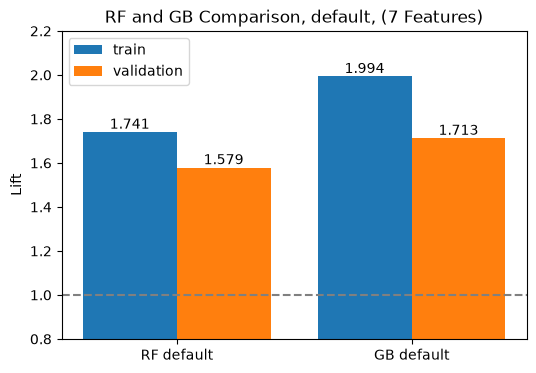

In [12]:
import numpy as np
import matplotlib.pyplot as plt

models = ["RF default", "GB default"]
train = [rf_default["train_lift"].iloc[0], gb_default["train_lift"].iloc[0]]
validation   = [rf_default["val_lift"].iloc[0],   gb_default["val_lift"].iloc[0]]

x = np.arange(len(models))                    

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(x - 0.2, train, width=0.4, label="train")
ax.bar(x + 0.2, validation,   width=0.4, label="validation")
ax.bar_label(ax.containers[0], fmt="%.3f")
ax.bar_label(ax.containers[1], fmt="%.3f")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.axhline(1.0, color="gray", linestyle="--")   
ax.set_ylim(0.8, 2.2)
ax.set_ylabel("Lift")
ax.set_title("RF and GB Comparison, default, (7 Features)")
ax.legend()


In [9]:
fig.savefig("../docs/figures/compare_rf_gb_default.png", dpi=150, bbox_inches="tight")

## Curves

Overlaid ROC / PR (or lift) for both models.

## Feature importance

Compare rankings; permutation importance for both.

## Training time and tuning effort


## Conclusion
